In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.utils.class_weight import compute_class_weight

import warnings
warnings.filterwarnings('ignore')

In [12]:
!pip install imbalanced-learn

In [13]:
# Dataset Loading

df = pd.read_csv(
    r"C:\DEV\Fake Job Prediction\Fake Job Dataset\fake_job_postings.csv")

base_path = r"C:\DEV\Fake Job Prediction\Fake Job Dataset\images"
df['webpage_screenshot'] = df.apply(
    lambda x: f"{base_path}/{x['fraudulent']}/{x['job_id']}.png",
    axis=1
)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

# First 5 rows
display(df.head())

# Dataset information
df.info()

Dataset loaded successfully.
Shape: (17880, 19)


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent,webpage_screenshot
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0,C:\DEV\Fake Job Prediction\Fake Job Dataset\im...
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0,C:\DEV\Fake Job Prediction\Fake Job Dataset\im...
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0,C:\DEV\Fake Job Prediction\Fake Job Dataset\im...
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0,C:\DEV\Fake Job Prediction\Fake Job Dataset\im...
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0,C:\DEV\Fake Job Prediction\Fake Job Dataset\im...


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   job_id               17880 non-null  int64 
 1   title                17880 non-null  object
 2   location             17534 non-null  object
 3   department           6333 non-null   object
 4   salary_range         2868 non-null   object
 5   company_profile      14572 non-null  object
 6   description          17879 non-null  object
 7   requirements         15184 non-null  object
 8   benefits             10668 non-null  object
 9   telecommuting        17880 non-null  int64 
 10  has_company_logo     17880 non-null  int64 
 11  has_questions        17880 non-null  int64 
 12  employment_type      14409 non-null  object
 13  required_experience  10830 non-null  object
 14  required_education   9775 non-null   object
 15  industry             12977 non-null  object
 16  func

In [14]:
# Check missing values
missing = df.isnull().sum().sort_values(ascending=False)

display(missing[missing > 0])

salary_range           15012
department             11547
required_education      8105
benefits                7212
required_experience     7050
function                6455
industry                4903
employment_type         3471
company_profile         3308
requirements            2696
location                 346
description                1
dtype: int64

Fraudulent Job Distribution:
fraudulent
0    17014
1      866
Name: count, dtype: int64

Percentage Distribution:
fraudulent
0    95.1566
1     4.8434
Name: proportion, dtype: float64


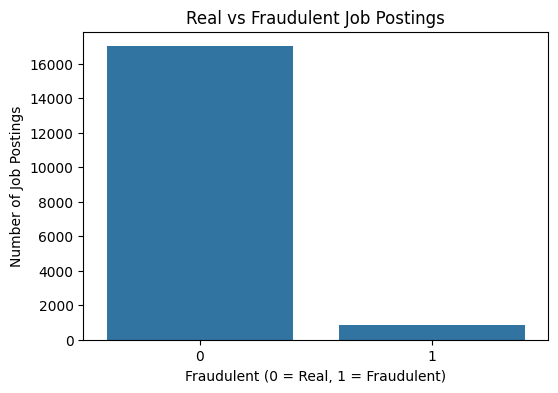

In [15]:
print("Fraudulent Job Distribution:")
print(df['fraudulent'].value_counts())

print("\nPercentage Distribution:")
print(df['fraudulent'].value_counts(normalize=True) * 100) 

# Here 0 is real and 1 is fake job postings.

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='fraudulent')

plt.title("Real vs Fraudulent Job Postings")
plt.xlabel("Fraudulent (0 = Real, 1 = Fraudulent)")
plt.ylabel("Number of Job Postings")

plt.show()

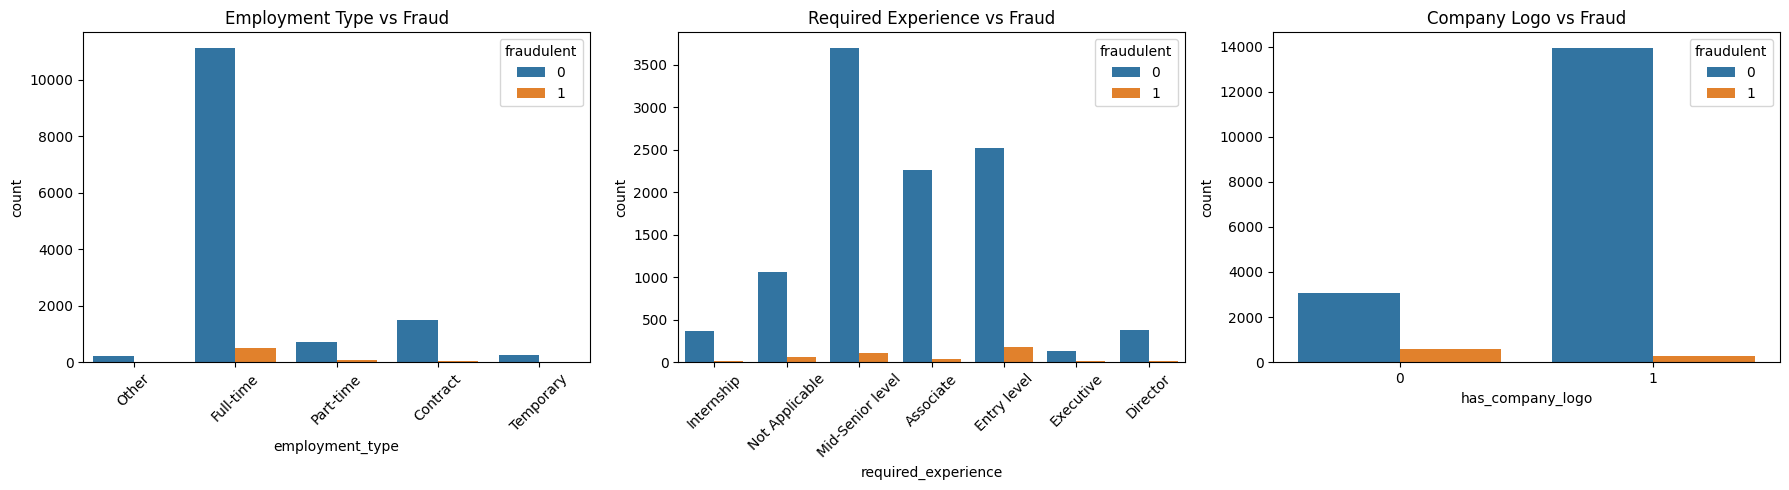

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(
    data=df,
    x='employment_type',
    hue='fraudulent',
    ax=axes[0]
)
axes[0].set_title("Employment Type vs Fraud")
axes[0].tick_params(axis='x', rotation=45)

sns.countplot(
    data=df,
    x='required_experience',
    hue='fraudulent',
    ax=axes[1]
)
axes[1].set_title("Required Experience vs Fraud")
axes[1].tick_params(axis='x', rotation=45)

sns.countplot(
    data=df,
    x='has_company_logo',
    hue='fraudulent',
    ax=axes[2]
)
axes[2].set_title("Company Logo vs Fraud")

plt.tight_layout()
plt.show()

In [17]:
text_features = [
    'title',
    'location',
    'department',
    'company_profile',
    'description',
    'requirements',
    'benefits'
]

df['text'] = (
    df[text_features]
    .fillna("")
    .agg(" ".join, axis=1)
)

              count        mean         std  min     25%    50%     75%  \
fraudulent                                                                
0           17014.0  383.100623  206.924463  8.0  239.00  358.0  499.00   
1             866.0  285.989607  204.266269  4.0  136.25  230.5  387.75   

               max  
fraudulent          
0           2121.0  
1           1343.0  


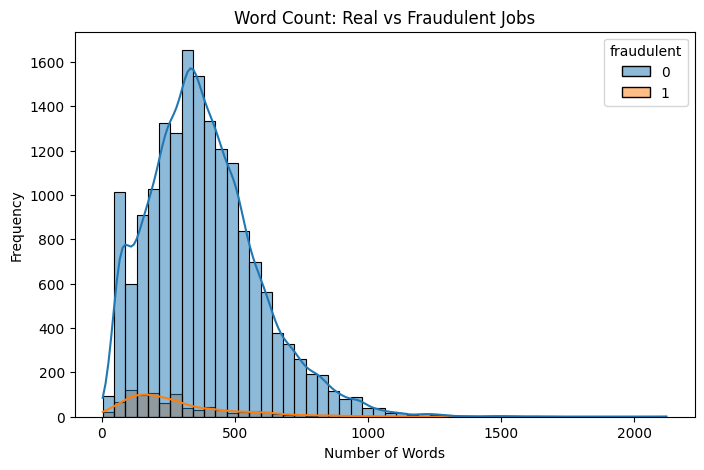

In [18]:
# Calculate number of words
df['word_count'] = df['text'].str.split().str.len()

print(df.groupby('fraudulent')['word_count'].describe())


plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='word_count',
    hue='fraudulent',
    bins=50,
    kde=True
)

plt.title("Word Count: Real vs Fraudulent Jobs")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

Here the EDA was ended and now we will move towards tha data preprocessing

In [19]:
base_path = r"C:\DEV\Fake Job Prediction\Fake Job Dataset\images"
df['webpage_screenshot'] = df.apply(
    lambda row: f"{base_path}\\{row['fraudulent']}\\{row['job_id']}.png",
    axis=1
)

In [20]:
# Check the mapping
display(
    df[['job_id', 'fraudulent', 'webpage_screenshot']].head(10)
)

,job_id,fraudulent,webpage_screenshot
0,1,0,C:\DEV\Fake Job Prediction\Fake Job Dataset\im...
1,2,0,C:\DEV\Fake Job Prediction\Fake Job Dataset\im...
2,3,0,C:\DEV\Fake Job Prediction\Fake Job Dataset\im...
3,4,0,C:\DEV\Fake Job Prediction\Fake Job Dataset\im...
4,5,0,C:\DEV\Fake Job Prediction\Fake Job Dataset\im...
5,6,0,C:\DEV\Fake Job Prediction\Fake Job Dataset\im...
6,7,0,C:\DEV\Fake Job Prediction\Fake Job Dataset\im...
7,8,0,C:\DEV\Fake Job Prediction\Fake Job Dataset\im...
8,9,0,C:\DEV\Fake Job Prediction\Fake Job Dataset\im...
9,10,0,C:\DEV\Fake Job Prediction\Fake Job Dataset\im...


In [21]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df['fraudulent'],
    random_state=42
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training data:", train_df.shape)
print("Testing data:", test_df.shape)

Training data: (14304, 21)
Testing data: (3576, 21)


In [22]:
print("Training distribution:")
print(train_df['fraudulent'].value_counts())

print("\nTesting distribution:")
print(test_df['fraudulent'].value_counts())

Training distribution:
fraudulent
0    13611
1      693
Name: count, dtype: int64

Testing distribution:
fraudulent
0    3403
1     173
Name: count, dtype: int64


In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    max_features=1000,
    ngram_range=(1, 2)
)

# Learn vocabulary ONLY from training data
tfidf_features_train = tfidf_vectorizer.fit_transform(
    train_df['text']
).toarray()

# Apply the same vocabulary to test data
tfidf_features_test = tfidf_vectorizer.transform(
    test_df['text']
).toarray()

print("TF-IDF train shape:", tfidf_features_train.shape)
print("TF-IDF test shape:", tfidf_features_test.shape)

TF-IDF train shape: (14304, 1000)
TF-IDF test shape: (3576, 1000)


In [24]:
from imblearn.over_sampling import SMOTE, ADASYN

# Target variable
y_train = train_df['fraudulent'].values
y_test = test_df['fraudulent'].values

print("Before balancing:")
print(pd.Series(y_train).value_counts())

# SMOTE
smote = SMOTE(
    random_state=42,
    k_neighbors=5
)

X_train_smote, y_train_smote = smote.fit_resample(
    tfidf_features_train,
    y_train
)

print("\nAfter SMOTE:")
print(pd.Series(y_train_smote).value_counts())

print("\nTraining shape before:", tfidf_features_train.shape)
print("Training shape after :", X_train_smote.shape)

Before balancing:
0    13611
1      693
Name: count, dtype: int64

After SMOTE:
0    13611
1    13611
Name: count, dtype: int64

Training shape before: (14304, 1000)
Training shape after : (27222, 1000)


In [25]:
# import numpy as np
# from sklearn.utils.class_weight import compute_class_weight

# class_weights = compute_class_weight(
#     class_weight='balanced',
#     classes=np.unique(train_df['fraudulent']),
#     y=train_df['fraudulent']
# )

# print("Class weights:", class_weights)

In [26]:
# import torch

# class_weight_tensor = torch.FloatTensor(class_weights)

# print("PyTorch class weights:", class_weight_tensor)

In [27]:
from imblearn.over_sampling import ADASYN

# ADASYN
adasyn = ADASYN(
    random_state=42,
    n_neighbors=5
)

X_train_adasyn, y_train_adasyn = adasyn.fit_resample(
    tfidf_features_train,
    y_train
)

print("Before balancing:")
print(pd.Series(y_train).value_counts())

print("\nAfter ADASYN:")
print(pd.Series(y_train_adasyn).value_counts())

print("\nTraining shape before:", tfidf_features_train.shape)
print("Training shape after :", X_train_adasyn.shape)

Before balancing:
0    13611
1      693
Name: count, dtype: int64

After ADASYN:
0    13611
1    13611
Name: count, dtype: int64

Training shape before: (14304, 1000)
Training shape after : (27222, 1000)


In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score
)

# Create model
lr_smote = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Train on SMOTE-balanced training data
lr_smote.fit(X_train_smote, y_train_smote)

# Predict on ORIGINAL test data
y_pred_smote = lr_smote.predict(tfidf_features_test)
y_prob_smote = lr_smote.predict_proba(tfidf_features_test)[:, 1]

print("===== SMOTE RESULTS =====")
print("Accuracy:", accuracy_score(y_test, y_pred_smote))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_smote))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_smote))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_smote))

===== SMOTE RESULTS =====
Accuracy: 0.9549776286353467
ROC-AUC: 0.9750984765227554

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.96      0.98      3403
           1       0.52      0.88      0.65       173

    accuracy                           0.95      3576
   macro avg       0.76      0.92      0.81      3576
weighted avg       0.97      0.95      0.96      3576


Confusion Matrix:
[[3263  140]
 [  21  152]]


In [29]:
lr_adasyn = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Train on ADASYN-balanced training data
lr_adasyn.fit(X_train_adasyn, y_train_adasyn)

# Predict on ORIGINAL test data
y_pred_adasyn = lr_adasyn.predict(tfidf_features_test)
y_prob_adasyn = lr_adasyn.predict_proba(tfidf_features_test)[:, 1]

print("===== ADASYN RESULTS =====")
print("Accuracy:", accuracy_score(y_test, y_pred_adasyn))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_adasyn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_adasyn))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_adasyn))

===== ADASYN RESULTS =====
Accuracy: 0.9365212527964206
ROC-AUC: 0.9710812798635682

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.94      0.97      3403
           1       0.43      0.90      0.58       173

    accuracy                           0.94      3576
   macro avg       0.71      0.92      0.77      3576
weighted avg       0.97      0.94      0.95      3576


Confusion Matrix:
[[3194  209]
 [  18  155]]


In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Train on ORIGINAL, imbalanced training data
lr_normal = LogisticRegression(
    max_iter=2000,
    random_state=42
)

lr_normal.fit(tfidf_features_train, y_train)

# Predict on ORIGINAL test data
y_pred_normal = lr_normal.predict(tfidf_features_test)
y_prob_normal = lr_normal.predict_proba(tfidf_features_test)[:, 1]

print("===== NORMAL DATA RESULTS =====")

print("Accuracy:", accuracy_score(y_test, y_pred_normal))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_normal))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_normal))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_normal))

===== NORMAL DATA RESULTS =====
Accuracy: 0.9672818791946308
ROC-AUC: 0.9655438333058726

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      3403
           1       0.94      0.35      0.51       173

    accuracy                           0.97      3576
   macro avg       0.95      0.67      0.74      3576
weighted avg       0.97      0.97      0.96      3576


Confusion Matrix:
[[3399    4]
 [ 113   60]]


In [31]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Calculate metrics for each method
results = {
    "Normal": {
        "Accuracy": accuracy_score(y_test, y_pred_normal),
        "Precision": precision_score(y_test, y_pred_normal, zero_division=0),
        "Recall": recall_score(y_test, y_pred_normal, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred_normal, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob_normal)
    },

    "SMOTE": {
        "Accuracy": accuracy_score(y_test, y_pred_smote),
        "Precision": precision_score(y_test, y_pred_smote, zero_division=0),
        "Recall": recall_score(y_test, y_pred_smote, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred_smote, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob_smote)
    },

    "ADASYN": {
        "Accuracy": accuracy_score(y_test, y_pred_adasyn),
        "Precision": precision_score(y_test, y_pred_adasyn, zero_division=0),
        "Recall": recall_score(y_test, y_pred_adasyn, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred_adasyn, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob_adasyn)
    }
}

# Create comparison DataFrame
comparison_df = pd.DataFrame(results).T

# Round values
comparison_df = comparison_df.round(4)

print("===== MODEL COMPARISON =====")
display(comparison_df)

===== MODEL COMPARISON =====


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Normal,0.9673,0.9375,0.3468,0.5063,0.9655
SMOTE,0.9550,0.5205,0.8786,0.6538,0.9751
ADASYN,0.9365,0.4258,0.8960,0.5773,0.9711


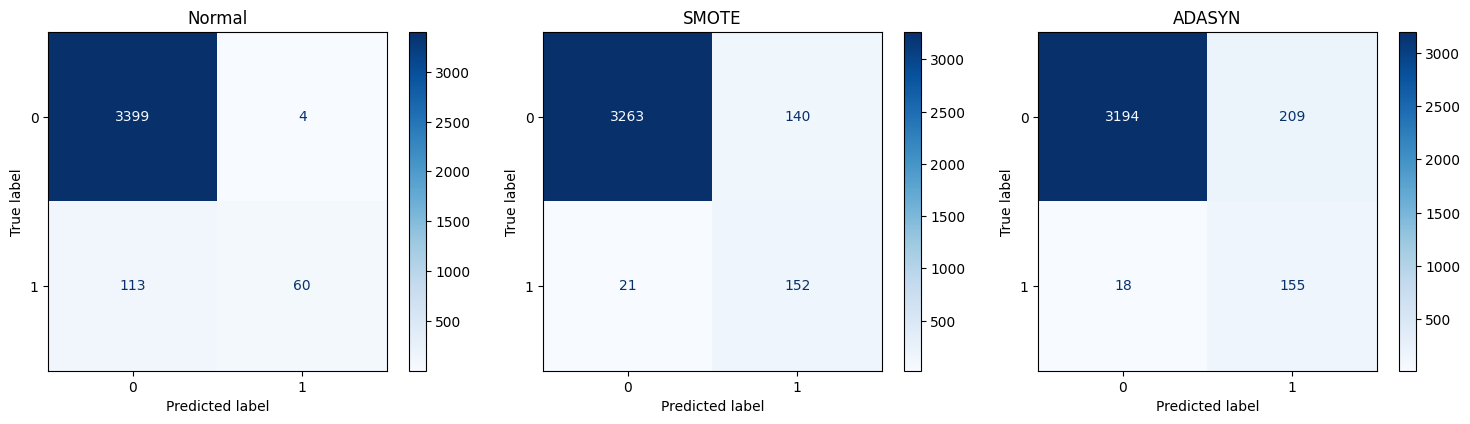

In [32]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Normal
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_normal,
    ax=axes[0],
    cmap="Blues"
)
axes[0].set_title("Normal")

# SMOTE
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_smote,
    ax=axes[1],
    cmap="Blues"
)
axes[1].set_title("SMOTE")

# ADASYN
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_adasyn,
    ax=axes[2],
    cmap="Blues"
)
axes[2].set_title("ADASYN")

plt.tight_layout()
plt.show()

In [33]:
from sklearn.metrics import confusion_matrix
import pandas as pd

def get_cm_values(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tn, fp, fn, tp

tn_n, fp_n, fn_n, tp_n = get_cm_values(y_test, y_pred_normal)
tn_s, fp_s, fn_s, tp_s = get_cm_values(y_test, y_pred_smote)
tn_a, fp_a, fn_a, tp_a = get_cm_values(y_test, y_pred_adasyn)

final_comparison = pd.DataFrame({
    "Method": ["Normal", "SMOTE", "ADASYN"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_normal),
        accuracy_score(y_test, y_pred_smote),
        accuracy_score(y_test, y_pred_adasyn)
    ],
    "Precision": [
        precision_score(y_test, y_pred_normal),
        precision_score(y_test, y_pred_smote),
        precision_score(y_test, y_pred_adasyn)
    ],
    "Recall": [
        recall_score(y_test, y_pred_normal),
        recall_score(y_test, y_pred_smote),
        recall_score(y_test, y_pred_adasyn)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred_normal),
        f1_score(y_test, y_pred_smote),
        f1_score(y_test, y_pred_adasyn)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_normal),
        roc_auc_score(y_test, y_prob_smote),
        roc_auc_score(y_test, y_prob_adasyn)
    ],
    "False Positives": [fp_n, fp_s, fp_a],
    "False Negatives": [fn_n, fn_s, fn_a]
})

final_comparison.round(4)

,Method,Accuracy,Precision,Recall,F1-Score,ROC-AUC,False Positives,False Negatives
0,Normal,0.9673,0.9375,0.3468,0.5063,0.9655,4,113
1,SMOTE,0.9550,0.5205,0.8786,0.6538,0.9751,140,21
2,ADASYN,0.9365,0.4258,0.8960,0.5773,0.9711,209,18


In [34]:
import torch
import torch.nn as nn
import torch.optim as optim

import transformers

print("Transformers version:", transformers.__version__)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

Transformers version: 5.15.0
PyTorch version: 2.11.0+cu128
CUDA available: True


In [35]:
class MultiKernelBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()

        mid = out_ch // 3

        self.b3 = nn.Conv2d(
            in_ch, mid, kernel_size=3, padding=1, bias=False
        )

        self.b5 = nn.Conv2d(
            in_ch, mid, kernel_size=5, padding=2, bias=False
        )

        self.b7 = nn.Conv2d(
            in_ch, out_ch - 2 * mid,
            kernel_size=7, padding=3, bias=False
        )

        self.bn = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)

        if in_ch != out_ch:
            self.short = nn.Conv2d(
                in_ch, out_ch, kernel_size=1, bias=False
            )
        else:
            self.short = nn.Identity()

    def forward(self, x):
        o1 = self.b3(x)
        o2 = self.b5(x)
        o3 = self.b7(x)

        out = torch.cat([o1, o2, o3], dim=1)
        out = self.bn(out)

        return self.relu(out + self.short(x))


print("MultiKernelBlock OK")

MultiKernelBlock OK


In [36]:
class MultiKernelResNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )

        self.l1 = nn.Sequential(
            MultiKernelBlock(64, 128),
            nn.MaxPool2d(2)
        )

        self.l2 = nn.Sequential(
            MultiKernelBlock(128, 256),
            nn.MaxPool2d(2)
        )

        self.l3 = nn.Sequential(
            MultiKernelBlock(256, 512),
            nn.MaxPool2d(2)
        )

        self.l4 = MultiKernelBlock(512, 512)

        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.out_dim = 512

    def forward(self, x):
        x = self.stem(x)
        x = self.l1(x)
        x = self.l2(x)
        x = self.l3(x)
        x = self.l4(x)
        x = self.pool(x)

        return torch.flatten(x, 1)


print("MultiKernelResNet OK")

MultiKernelResNet OK


In [37]:
from transformers import BertModel

# Load pretrained BERT
bert = BertModel.from_pretrained("bert-base-uncased")

# Freeze BERT parameters
for param in bert.parameters():
    param.requires_grad = False

# Create our custom CNN
resnet = MultiKernelResNet()

print("BERT loaded successfully.")
print("BERT parameters frozen.")
print("ResNet created successfully.")
print("ResNet output dimension:", resnet.out_dim)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT loaded successfully.
BERT parameters frozen.
ResNet created successfully.
ResNet output dimension: 512


In [39]:
class MultiModalClassifier(nn.Module):
    def __init__(
        self,
        bert,
        resnet,
        tfidf_dim=1000,
        bow_dim=500,
        dropout_rate=0.4
    ):
        super().__init__()

        self.bert = bert
        self.resnet = resnet

        # -------------------------
        # TF-IDF branch
        # -------------------------
        self.tfidf_fc = nn.Sequential(
            nn.Linear(tfidf_dim, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256),
            nn.Dropout(dropout_rate)
        )

        # -------------------------
        # BoW branch
        # -------------------------
        self.bow_fc = nn.Sequential(
            nn.Linear(bow_dim, 128),
            nn.ReLU(),
            nn.BatchNorm1d(128),
            nn.Dropout(dropout_rate)
        )

        # -------------------------
        # BERT branch
        # -------------------------
        self.bert_fc = nn.Sequential(
            nn.Linear(768, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256),
            nn.Dropout(dropout_rate)
        )

        # -------------------------
        # Image branch
        # -------------------------
        self.img_fc = nn.Sequential(
            nn.Linear(resnet.out_dim, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256),
            nn.Dropout(dropout_rate)
        )

        # -------------------------
        # Fusion
        # TF-IDF 256
        # BoW    128
        # BERT   256
        # Image  256
        # Total  896
        # -------------------------
        self.fusion_fc = nn.Sequential(
            nn.Linear(896, 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Dropout(dropout_rate),

            nn.Linear(512, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256),
            nn.Dropout(dropout_rate),

            nn.Linear(256, 2)
        )

        # Individual classifiers
        self.tfidf_classifier = nn.Linear(256, 2)
        self.bow_classifier = nn.Linear(128, 2)
        self.bert_classifier = nn.Linear(256, 2)
        self.img_classifier = nn.Linear(256, 2)

        # Learnable modality weights
        self.alpha = nn.Parameter(torch.tensor(1.0))
        self.beta = nn.Parameter(torch.tensor(1.0))
        self.gamma = nn.Parameter(torch.tensor(1.0))
        self.delta = nn.Parameter(torch.tensor(1.0))

    def forward(
        self,
        input_ids,
        mask,
        images,
        tfidf_feats,
        bow_feats
    ):

        # -------------------------
        # BERT features
        # -------------------------
        with torch.no_grad():
            bert_output = self.bert(
                input_ids=input_ids,
                attention_mask=mask
            ).pooler_output

        # -------------------------
        # Image features
        # -------------------------
        img_feat = self.resnet(images)

        # -------------------------
        # Process modalities
        # -------------------------
        tfidf_p = self.tfidf_fc(tfidf_feats)
        bow_p = self.bow_fc(bow_feats)
        bert_p = self.bert_fc(bert_output)
        img_p = self.img_fc(img_feat)

        # -------------------------
        # Individual predictions
        # -------------------------
        tfidf_logits = self.tfidf_classifier(tfidf_p)
        bow_logits = self.bow_classifier(bow_p)
        bert_logits = self.bert_classifier(bert_p)
        img_logits = self.img_classifier(img_p)

        # -------------------------
        # Feature fusion
        # -------------------------
        combined = torch.cat(
            [tfidf_p, bow_p, bert_p, img_p],
            dim=1
        )

        fusion_logits = self.fusion_fc(combined)

        return (
            fusion_logits,
            tfidf_logits,
            bow_logits,
            bert_logits,
            img_logits
        )


print("MultiModalClassifier defined successfully.")

MultiModalClassifier defined successfully.


In [40]:
model = MultiModalClassifier(
    bert=bert,
    resnet=resnet
).to(device)

print("Model device:", next(model.parameters()).device)

Model device: cuda:0


In [41]:
# Step 6: Create model

device = "cuda" if torch.cuda.is_available() else "cpu"

model = MultiModalClassifier(
    bert=bert,
    resnet=resnet
).to(device)

print("Device:", device)
print("Model created successfully.")

Device: cuda
Model created successfully.


In [ ]:
# Step 6B: Optimizer

optimizer = torch.optim.AdamW(
    [
        {'params': model.tfidf_fc.parameters(), 'lr': 3e-4},
        {'params': model.bow_fc.parameters(), 'lr': 3e-4},
        {'params': model.bert_fc.parameters(), 'lr': 1e-4},
        {'params': model.img_fc.parameters(), 'lr': 1e-4},
        {'params': model.resnet.parameters(), 'lr': 1e-5},
        {'params': model.fusion_fc.parameters(), 'lr': 2e-4},
        {'params': model.tfidf_classifier.parameters(), 'lr': 3e-4},
        {'params': model.bow_classifier.parameters(), 'lr': 3e-4},
        {'params': model.bert_classifier.parameters(), 'lr': 2e-4},
        {'params': model.img_classifier.parameters(), 'lr': 2e-4},
        {
            'params': [
                model.alpha,
                model.beta,
                model.gamma,
                model.delta
            ],
            'lr': 1e-3
        }
    ],
    weight_decay=0.01
)

print("Optimizer created successfully.")

Optimizer created successfully.


In [ ]:
class AdaptiveMultiTaskLoss(nn.Module):
    def __init__(self, class_weights=None):
        super().__init__()

        self.crit = nn.CrossEntropyLoss(
            weight=class_weights
        )

    def forward(
        self,
        model,
        fusion_logits,
        tfidf_logits,
        bow_logits,
        bert_logits,
        img_logits,
        labels
    ):

        # Individual losses
        f_l = self.crit(fusion_logits, labels)
        t_l = self.crit(tfidf_logits, labels)
        b_l = self.crit(bow_logits, labels)
        bt_l = self.crit(bert_logits, labels)
        i_l = self.crit(img_logits, labels)

        # Learnable branch weights
        a = torch.exp(model.alpha)
        b = torch.exp(model.beta)
        g = torch.exp(model.gamma)
        d = torch.exp(model.delta)

        s = a + b + g + d

        an = a / s
        bn = b / s
        gn = g / s
        dn = d / s

        # Total loss
        total = (
            f_l
            + an * t_l
            + bn * b_l
            + gn * bt_l
            + dn * i_l
        )

        return (
            total,
            f_l,
            t_l,
            b_l,
            bt_l,
            i_l,
            an,
            bn,
            gn,
            dn
        )


print("AdaptiveMultiTaskLoss defined successfully.")

AdaptiveMultiTaskLoss defined successfully.


In [ ]:
import numpy as np
import torch
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_df['fraudulent']),
    y=train_df['fraudulent']
)

class_weight_tensor = torch.FloatTensor(class_weights)

print("Class weights:", class_weights)
print("PyTorch class weights:", class_weight_tensor)

Class weights: [ 0.52545735 10.32034632]
PyTorch class weights: tensor([ 0.5255, 10.3203])


In [ ]:
criterion = AdaptiveMultiTaskLoss(
    class_weights=class_weight_tensor.to(device)
)

print("Loss function created successfully.")

Loss function created successfully.


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

print("Dataset dependencies imported successfully.")

Dataset dependencies imported successfully.


In [ ]:
class JobDataset(Dataset):
    def __init__(
        self,
        df,
        tokenizer,
        tfidf_features,
        bow_features,
        max_len=256,
        augment=False
    ):
        self.df = df
        self.tokenizer = tokenizer
        self.max_len = max_len
        self.tfidf_features = tfidf_features
        self.bow_features = bow_features
        self.augment = augment

        if augment:
            self.transform = transforms.Compose([
                transforms.Resize((224, 224)),
                transforms.RandomHorizontalFlip(p=0.3),
                transforms.RandomRotation(10),
                transforms.ColorJitter(
                    brightness=0.3,
                    contrast=0.3,
                    saturation=0.2
                ),
                transforms.ToTensor(),
                transforms.Normalize(
                    mean=[0.485, 0.456, 0.406],
                    std=[0.229, 0.224, 0.225]
                )
            ])
        else:
            self.transform = transforms.Compose([
                transforms.Resize((224, 224)),
                transforms.ToTensor(),
                transforms.Normalize(
                    mean=[0.485, 0.456, 0.406],
                    std=[0.229, 0.224, 0.225]
                )
            ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        enc = self.tokenizer(
            row['text'],
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt"
        )

        img_path = row['webpage_screenshot']

        try:
            img = Image.open(img_path).convert("RGB")
        except:
            img = Image.new(
                "RGB",
                (224, 224),
                color=(128, 128, 128)
            )

        img = self.transform(img)

        tfidf_feat = torch.FloatTensor(
            self.tfidf_features[idx]
        )

        bow_feat = torch.FloatTensor(
            self.bow_features[idx]
        )

        return (
            enc["input_ids"].squeeze(0),
            enc["attention_mask"].squeeze(0),
            img,
            tfidf_feat,
            bow_feat,
            torch.tensor(
                row['fraudulent'],
                dtype=torch.long
            )
        )


print("JobDataset defined successfully.")

JobDataset defined successfully.


In [ ]:
from transformers import BertTokenizer

tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

print("Tokenizer created successfully.")

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer created successfully.


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

bow_vectorizer = CountVectorizer(
    max_features=500,
    binary=True
)

bow_features_train = bow_vectorizer.fit_transform(
    train_df['text']
).toarray()

bow_features_test = bow_vectorizer.transform(
    test_df['text']
).toarray()

print("BoW train shape:", bow_features_train.shape)
print("BoW test shape :", bow_features_test.shape)

BoW train shape: (14304, 500)
BoW test shape : (3576, 500)


In [ ]:
train_dataset = JobDataset(
    train_df,
    tokenizer,
    tfidf_features_train,
    bow_features_train,
    augment=True
)

test_dataset = JobDataset(
    test_df,
    tokenizer,
    tfidf_features_test,
    bow_features_test,
    augment=False
)

print("Train dataset:", len(train_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 14304
Test dataset: 3576


In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

print("Train loader:", len(train_loader), "batches")
print("Test loader :", len(test_loader), "batches")

Train loader: 894 batches
Test loader : 224 batches


In [ ]:
# Step 8: Train the multimodal model

num_epochs = 1

for epoch in range(num_epochs):

    # -------------------------
    # TRAINING
    # -------------------------
    model.train()

    train_loss = 0.0

    for ids, mask, imgs, tfidf_feats, bow_feats, labels in train_loader:

        ids = ids.to(device)
        mask = mask.to(device)
        imgs = imgs.to(device)
        tfidf_feats = tfidf_feats.to(device)
        bow_feats = bow_feats.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        # Forward pass
        (
            fusion_logits,
            tfidf_logits,
            bow_logits,
            bert_logits,
            img_logits
        ) = model(
            ids,
            mask,
            imgs,
            tfidf_feats,
            bow_feats
        )

        # Calculate loss
        loss, *_ = criterion(
            model,
            fusion_logits,
            tfidf_logits,
            bow_logits,
            bert_logits,
            img_logits,
            labels
        )

        # Backpropagation
        loss.backward()

        # Prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        train_loss += loss.item()

    # Average training loss
    train_loss /= len(train_loader)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Training Loss: {train_loss:.4f}"
    )

: 

: 

In [43]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [44]:
optimizer = torch.optim.AdamW(
    [
        {'params': model.tfidf_fc.parameters(), 'lr': 3e-4},
        {'params': model.bow_fc.parameters(), 'lr': 3e-4},
        {'params': model.bert_fc.parameters(), 'lr': 1e-4},
        {'params': model.img_fc.parameters(), 'lr': 1e-4},

        # CNN
        {'params': model.resnet.parameters(), 'lr': 1e-5},

        # Fusion
        {'params': model.fusion_fc.parameters(), 'lr': 2e-4},

        # Individual classifiers
        {'params': model.tfidf_classifier.parameters(), 'lr': 3e-4},
        {'params': model.bow_classifier.parameters(), 'lr': 3e-4},
        {'params': model.bert_classifier.parameters(), 'lr': 2e-4},
        {'params': model.img_classifier.parameters(), 'lr': 2e-4},

        # Learnable modality weights
        {
            'params': [
                model.alpha,
                model.beta,
                model.gamma,
                model.delta
            ],
            'lr': 1e-3
        }
    ],
    weight_decay=0.01
)

print("Optimizer created successfully.")

Optimizer created successfully.


In [45]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_df["fraudulent"]),
    y=train_df["fraudulent"]
)

class_weight_tensor = torch.FloatTensor(class_weights).to(device)

print("Class weights:", class_weight_tensor)

Class weights: tensor([ 0.5255, 10.3203], device='cuda:0')


In [46]:
class AdaptiveMultiTaskLoss(nn.Module):
    def __init__(self, class_weights=None):
        super().__init__()

        self.crit = nn.CrossEntropyLoss(
            weight=class_weights
        )

    def forward(
        self,
        model,
        fusion_logits,
        tfidf_logits,
        bow_logits,
        bert_logits,
        img_logits,
        labels
    ):

        f_l = self.crit(fusion_logits, labels)
        t_l = self.crit(tfidf_logits, labels)
        b_l = self.crit(bow_logits, labels)
        bt_l = self.crit(bert_logits, labels)
        i_l = self.crit(img_logits, labels)

        a = torch.exp(model.alpha)
        b = torch.exp(model.beta)
        g = torch.exp(model.gamma)
        d = torch.exp(model.delta)

        s = a + b + g + d

        an = a / s
        bn = b / s
        gn = g / s
        dn = d / s

        total = (
            f_l
            + an * t_l
            + bn * b_l
            + gn * bt_l
            + dn * i_l
        )

        return (
            total,
            f_l,
            t_l,
            b_l,
            bt_l,
            i_l,
            an,
            bn,
            gn,
            dn
        )


criterion = AdaptiveMultiTaskLoss(
    class_weights=class_weight_tensor
)

print("Loss function created successfully.")

Loss function created successfully.


In [48]:
from torch.utils.data import DataLoader

print("DataLoader imported successfully.")

DataLoader imported successfully.


In [51]:
from torch.utils.data import Dataset
from torchvision import transforms
from PIL import Image

class JobDataset(Dataset):
    def __init__(
        self,
        df,
        tokenizer,
        tfidf_features,
        bow_features,
        max_len=256,
        augment=False
    ):
        self.df = df
        self.tokenizer = tokenizer
        self.max_len = max_len
        self.tfidf_features = tfidf_features
        self.bow_features = bow_features
        self.augment = augment

        if augment:
            self.transform = transforms.Compose([
                transforms.Resize((224, 224)),
                transforms.RandomHorizontalFlip(p=0.3),
                transforms.RandomRotation(10),
                transforms.ColorJitter(
                    brightness=0.3,
                    contrast=0.3,
                    saturation=0.2
                ),
                transforms.ToTensor(),
                transforms.Normalize(
                    mean=[0.485, 0.456, 0.406],
                    std=[0.229, 0.224, 0.225]
                )
            ])
        else:
            self.transform = transforms.Compose([
                transforms.Resize((224, 224)),
                transforms.ToTensor(),
                transforms.Normalize(
                    mean=[0.485, 0.456, 0.406],
                    std=[0.229, 0.224, 0.225]
                )
            ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        enc = self.tokenizer(
            row["text"],
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt"
        )

        img_path = row["webpage_screenshot"]

        try:
            img = Image.open(img_path).convert("RGB")
        except:
            img = Image.new(
                "RGB",
                (224, 224),
                color=(128, 128, 128)
            )

        img = self.transform(img)

        tfidf_feat = torch.FloatTensor(
            self.tfidf_features[idx]
        )

        bow_feat = torch.FloatTensor(
            self.bow_features[idx]
        )

        return (
            enc["input_ids"].squeeze(0),
            enc["attention_mask"].squeeze(0),
            img,
            tfidf_feat,
            bow_feat,
            torch.tensor(
                row["fraudulent"],
                dtype=torch.long
            )
        )

print("JobDataset defined successfully.")

JobDataset defined successfully.


In [53]:
from transformers import BertTokenizer

tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

print("Tokenizer ready.")

Tokenizer ready.


In [55]:
from sklearn.feature_extraction.text import CountVectorizer

bow_vectorizer = CountVectorizer(
    max_features=500,
    binary=True
)

bow_features_train = bow_vectorizer.fit_transform(
    train_df["text"]
).toarray()

bow_features_test = bow_vectorizer.transform(
    test_df["text"]
).toarray()

print("BoW train shape:", bow_features_train.shape)
print("BoW test shape:", bow_features_test.shape)

BoW train shape: (14304, 500)
BoW test shape: (3576, 500)


In [56]:
train_dataset = JobDataset(
    train_df,
    tokenizer,
    tfidf_features_train,
    bow_features_train,
    augment=True
)

test_dataset = JobDataset(
    test_df,
    tokenizer,
    tfidf_features_test,
    bow_features_test,
    augment=False
)

print("Train dataset:", len(train_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 14304
Test dataset: 3576


In [57]:
# Step 11: Create DataLoaders

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Test batches :", len(test_loader))

Train batches: 894
Test batches : 224


In [58]:
# Step 12: 1-epoch GPU training test

import time

num_epochs = 1

start_time = time.time()

model.train()
train_loss = 0.0

for batch_idx, (ids, mask, imgs, tfidf_feats, bow_feats, labels) in enumerate(train_loader):

    ids = ids.to(device)
    mask = mask.to(device)
    imgs = imgs.to(device)
    tfidf_feats = tfidf_feats.to(device)
    bow_feats = bow_feats.to(device)
    labels = labels.to(device)

    optimizer.zero_grad()

    # Forward pass
    (
        fusion_logits,
        tfidf_logits,
        bow_logits,
        bert_logits,
        img_logits
    ) = model(
        ids,
        mask,
        imgs,
        tfidf_feats,
        bow_feats
    )

    # Loss
    loss, *_ = criterion(
        model,
        fusion_logits,
        tfidf_logits,
        bow_logits,
        bert_logits,
        img_logits,
        labels
    )

    # Backpropagation
    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=1.0
    )

    optimizer.step()

    train_loss += loss.item()

    # Progress every 100 batches
    if (batch_idx + 1) % 100 == 0:
        print(
            f"Batch [{batch_idx + 1}/{len(train_loader)}]"
        )

train_loss /= len(train_loader)

elapsed = time.time() - start_time

print("\n===== TRAINING COMPLETE =====")
print("Training Loss:", round(train_loss, 4))
print("Time:", round(elapsed / 60, 2), "minutes")

Batch [100/894]
Batch [200/894]
Batch [300/894]
Batch [400/894]
Batch [500/894]
Batch [600/894]
Batch [700/894]
Batch [800/894]

===== TRAINING COMPLETE =====
Training Loss: 1.0229
Time: 12.36 minutes


In [59]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

model.eval()

all_labels = []
all_preds = []
all_probs = []

with torch.no_grad():

    for ids, mask, imgs, tfidf_feats, bow_feats, labels in test_loader:

        ids = ids.to(device)
        mask = mask.to(device)
        imgs = imgs.to(device)
        tfidf_feats = tfidf_feats.to(device)
        bow_feats = bow_feats.to(device)
        labels = labels.to(device)

        # Forward pass
        (
            fusion_logits,
            tfidf_logits,
            bow_logits,
            bert_logits,
            img_logits
        ) = model(
            ids,
            mask,
            imgs,
            tfidf_feats,
            bow_feats
        )

        # Final prediction
        probs = torch.softmax(fusion_logits, dim=1)

        preds = torch.argmax(
            fusion_logits,
            dim=1
        )

        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs[:, 1].cpu().numpy())


# Convert to arrays
all_labels = np.array(all_labels)
all_preds = np.array(all_preds)
all_probs = np.array(all_probs)


# Metrics
accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(
    all_labels,
    all_preds,
    zero_division=0
)
recall = recall_score(
    all_labels,
    all_preds,
    zero_division=0
)
f1 = f1_score(
    all_labels,
    all_preds,
    zero_division=0
)
roc_auc = roc_auc_score(
    all_labels,
    all_probs
)

print("===== MULTIMODAL MODEL RESULTS =====")

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\n===== CLASSIFICATION REPORT =====")
print(
    classification_report(
        all_labels,
        all_preds,
        target_names=["Real", "Fraud"],
        zero_division=0
    )
)

print("\n===== CONFUSION MATRIX =====")
print(confusion_matrix(all_labels, all_preds))

===== MULTIMODAL MODEL RESULTS =====
Accuracy : 0.9757
Precision: 0.8209
Recall   : 0.6358
F1-Score : 0.7166
ROC-AUC  : 0.9196

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

        Real       0.98      0.99      0.99      3403
       Fraud       0.82      0.64      0.72       173

    accuracy                           0.98      3576
   macro avg       0.90      0.81      0.85      3576
weighted avg       0.97      0.98      0.97      3576


===== CONFUSION MATRIX =====
[[3379   24]
 [  63  110]]
